# NIH ChestX-ray14 Dataset Processing Notes

## Project goal

This notebook prepares the NIH ChestX-ray14 dataset for a multi-label chest X-ray classification project comparing:

- ResNet-50
- MobileNetV3
- DeiT-Small

The notebook creates patient-level train/validation/test splits, encodes the 14 disease labels, checks class imbalance, visualizes samples, and builds a PyTorch `Dataset` for a smoke test.

## 1. Why this is a multi-label problem

One X-ray can contain more than one finding. For example, an image may be labeled `Effusion|Cardiomegaly`. Therefore, the target is a vector of 14 binary values, not one class ID.

`No Finding` is not one of the 14 disease outputs. It means that all 14 disease indicators are zero.

The most important data rule is **patient-level splitting**. A patient can have multiple images. Images from the same patient must not appear in different splits, or the test score may be artificially optimistic because of patient leakage.

In [1]:
# If packages are missing, run this cell once in Jupyter.
# %pip install pandas numpy matplotlib pillow scikit-learn torch torchvision seaborn

from pathlib import Path
import os
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## 2. Set the dataset paths

Change `DATA_ROOT` to the folder containing your NIH dataset. The expected arrangement is:

```text
DATA_ROOT/
├── Data_Entry_2017.csv
├── train_val_list.txt       # optional but recommended
├── test_list.txt            # optional but recommended
└── images/
    ├── 00000001_000.png
    └── ...
```

In [2]:
# EDIT THIS PATH.
# Example macOS path: Path('/Users/your_name/Downloads/ChestXray-NIHCC')
DATA_ROOT = Path('/Users/eric/Downloads/ChestXray-NIHCC')

METADATA_PATH = DATA_ROOT / 'Data_Entry_2017.csv'
TRAIN_VAL_LIST = DATA_ROOT / 'train_val_list.txt'
TEST_LIST = DATA_ROOT / 'test_list.txt'
OUTPUT_ROOT = DATA_ROOT / 'processed_data'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print('DATA_ROOT:', DATA_ROOT.resolve())
print('Metadata exists:', METADATA_PATH.exists())
print('train_val_list exists:', TRAIN_VAL_LIST.exists())
print('test_list exists:', TEST_LIST.exists())

DATA_ROOT: /Users/eric/Downloads/ChestXray-NIHCC
Metadata exists: True
train_val_list exists: True
test_list exists: True


## 3. Load and inspect the metadata

The metadata file contains one row per image. First inspect the column names, number of rows, missing values, and view positions before making any changes.

In [3]:
if not METADATA_PATH.exists():
    raise FileNotFoundError(
        f'Cannot find {METADATA_PATH}. Update DATA_ROOT in the previous cell.'
    )

raw_df = pd.read_csv(METADATA_PATH)
print('Rows:', len(raw_df))
print('Columns:', list(raw_df.columns))
display(raw_df.head())

print('\nMissing values:')
display(raw_df.isna().sum().sort_values(ascending=False).head(15))

print('\nView positions:')
display(raw_df['View Position'].value_counts(dropna=False))

Rows: 112120
Columns: ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]']


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168



Missing values:


Image Index                    0
Finding Labels                 0
Follow-up #                    0
Patient ID                     0
Patient Age                    0
Patient Gender                 0
View Position                  0
OriginalImage[Width            0
Height]                        0
OriginalImagePixelSpacing[x    0
y]                             0
dtype: int64


View positions:


View Position
PA    67310
AP    44810
Name: count, dtype: int64

## 4. Define the 14 disease labels and encode them as binary columns

In [4]:
LABELS = [
    'Atelectasis',
    'Cardiomegaly',
    'Effusion',
    'Infiltration',
    'Mass',
    'Nodule',
    'Pneumonia',
    'Pneumothorax',
    'Consolidation',
    'Edema',
    'Emphysema',
    'Fibrosis',
    'Pleural_Thickening',
    'Hernia',
]

def encode_labels(label_string):
    labels = set(str(label_string).split('|'))
    return [int(label in labels) for label in LABELS]

encoded = raw_df['Finding Labels'].apply(encode_labels)
df = raw_df.copy()
for i, label in enumerate(LABELS):
    df[label] = encoded.apply(lambda values: values[i])

print('Encoded label columns:', len(LABELS))
display(df[['Image Index', 'Finding Labels', 'Patient ID'] + LABELS].head())

Encoded label columns: 14


,Image Index,Finding Labels,Patient ID,Atelectasis,Cardiomegaly,Effusion,Infiltration,Mass,Nodule,Pneumonia,Pneumothorax,Consolidation,Edema,Emphysema,Fibrosis,Pleural_Thickening,Hernia
0,00000001_000.png,Cardiomegaly,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0
1,00000001_001.png,Cardiomegaly|Emphysema,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0
2,00000001_002.png,Cardiomegaly|Effusion,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0
3,00000002_000.png,No Finding,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,00000003_001.png,Hernia,3,0,0,0,0,0,0,0,0,0,0,0,0,0,1


## 5. Build image paths and check missing files

The image filename is stored in `Image Index`. We recursively index all image files so that the code works whether images are in one folder or several image folders.

In [5]:
IMAGE_EXTENSIONS = {'.png', '.jpg', '.jpeg'}
image_index = {}
for path in DATA_ROOT.rglob('*'):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        image_index[path.name] = path

print('Indexed image files:', len(image_index))

df['image_path'] = df['Image Index'].map(image_index)
missing_images = df['image_path'].isna()
print('Metadata rows with missing image files:', int(missing_images.sum()))

if missing_images.any():
    display(df.loc[missing_images, ['Image Index', 'Patient ID']].head())
    print('The missing files will be removed from the processed dataframe.')

df = df.loc[~missing_images].copy()
df['image_path'] = df['image_path'].astype(str)
df = df.drop_duplicates(subset=['Image Index']).reset_index(drop=True)
print('Usable rows after file check:', len(df))

Indexed image files: 112120
Metadata rows with missing image files: 0
Usable rows after file check: 112120


## 6. Basic dataset quality checks

Unique patients: 30805
Duplicate image names: 0
Duplicate patient-image pairs: 0

Disease prevalence:


,positive_percent
Infiltration,17.743
Effusion,11.877
Atelectasis,10.309
Nodule,5.647
Mass,5.157
Pneumothorax,4.729
Consolidation,4.163
Pleural_Thickening,3.019
Cardiomegaly,2.476
Emphysema,2.244


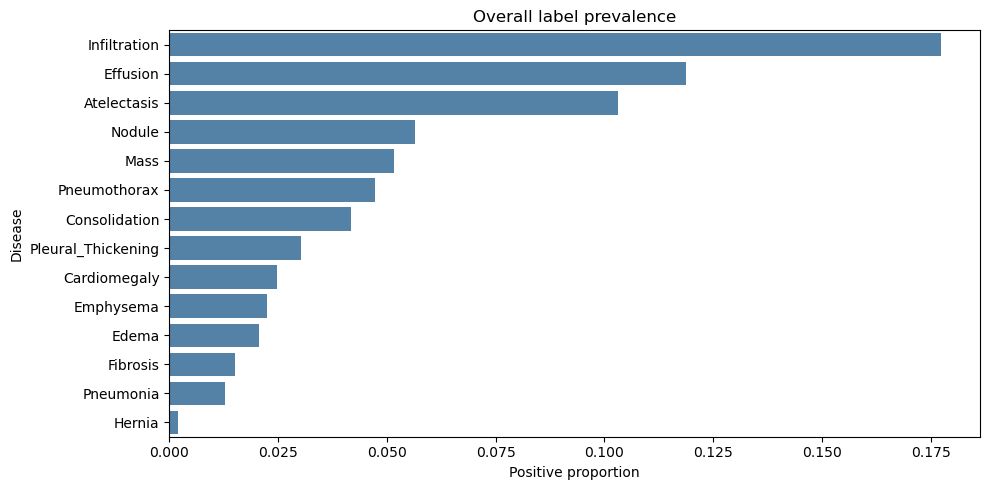

In [6]:
print('Unique patients:', df['Patient ID'].nunique())
print('Duplicate image names:', df['Image Index'].duplicated().sum())
print('Duplicate patient-image pairs:', df.duplicated(['Patient ID', 'Image Index']).sum())

print('\nDisease prevalence:')
prevalence = df[LABELS].mean().sort_values(ascending=False)
display((prevalence * 100).round(3).rename('positive_percent').to_frame())

plt.figure(figsize=(10, 5))
sns.barplot(x=prevalence.values, y=prevalence.index, color='steelblue')
plt.xlabel('Positive proportion')
plt.ylabel('Disease')
plt.title('Overall label prevalence')
plt.tight_layout()
plt.show()

## 7. Create patient-level train/validation/test splits

The official test list is kept untouched, and the train/validation portion is split by `Patient ID`.

If the official list files are not available, the fallback is a reproducible patient-level 70/15/15 split. The fallback is acceptable for a pipeline test, but the final report should document exactly which split was used.

In [7]:
from sklearn.model_selection import GroupShuffleSplit
from pathlib import Path

def normalize_filename(x):
    return Path(str(x).strip()).name

def read_image_list(path):
    return {
        normalize_filename(line)
        for line in path.read_text().splitlines()
        if line.strip()
    }

# Normalize metadata filenames
df["Image Index"] = df["Image Index"].apply(normalize_filename)

if TRAIN_VAL_LIST.exists() and TEST_LIST.exists():

    train_val_names = read_image_list(TRAIN_VAL_LIST)
    test_names = read_image_list(TEST_LIST)

    print("Metadata image examples:")
    print(df["Image Index"].head().tolist())

    print("\nTrain/validation list examples:")
    print(list(train_val_names)[:5])

    print("\nTest list examples:")
    print(list(test_names)[:5])

    train_val_df = df[df["Image Index"].isin(train_val_names)].copy()
    test_df = df[df["Image Index"].isin(test_names)].copy()

    print("\nMatched train/validation rows:", len(train_val_df))
    print("Matched test rows:", len(test_df))

    if len(train_val_df) == 0 or len(test_df) == 0:
        raise ValueError(
            "No filenames matched. Please check that Data_Entry_2017.csv, "
            "train_val_list.txt, and test_list.txt are from the same dataset version."
        )

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=SEED
    )

    train_idx, val_idx = next(
        splitter.split(
            train_val_df,
            groups=train_val_df["Patient ID"]
        )
    )

    train_df = train_val_df.iloc[train_idx].copy()
    val_df = train_val_df.iloc[val_idx].copy()

    split_method = "official test list + patient-level train/validation split"

else:
    print("Official split files not found. Using fallback patient-level split.")

    first_splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.30,
        random_state=SEED
    )

    train_idx, temp_idx = next(
        first_splitter.split(
            df,
            groups=df["Patient ID"]
        )
    )

    train_df = df.iloc[train_idx].copy()
    temp_df = df.iloc[temp_idx].copy()

    second_splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=SEED
    )

    val_idx, test_idx = next(
        second_splitter.split(
            temp_df,
            groups=temp_df["Patient ID"]
        )
    )

    val_df = temp_df.iloc[val_idx].copy()
    test_df = temp_df.iloc[test_idx].copy()

    split_method = "fallback patient-level 70/15/15 split"

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nSplit method:", split_method)
print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Metadata image examples:
['00000001_000.png', '00000001_001.png', '00000001_002.png', '00000002_000.png', '00000003_001.png']

Train/validation list examples:
['00005176_022.png', '00022596_005.png', '00023350_000.png', '00006242_003.png', '00001877_000.png']

Test list examples:
['00017981_022.png', '00001248_018.png', '00012298_005.png', '00023091_002.png', '00026562_014.png']

Matched train/validation rows: 86524
Matched test rows: 25596

Split method: official test list + patient-level train/validation split
Train images: 73916
Validation images: 12608
Test images: 25596


In [8]:
train_patients = set(train_df['Patient ID'])
val_patients = set(val_df['Patient ID'])
test_patients = set(test_df['Patient ID'])

overlap_table = pd.DataFrame({
    'train_validation': [len(train_patients & val_patients)],
    'train_test': [len(train_patients & test_patients)],
    'validation_test': [len(val_patients & test_patients)],
})
display(overlap_table)

assert len(train_patients & val_patients) == 0
assert len(train_patients & test_patients) == 0
assert len(val_patients & test_patients) == 0
print('PASS: no patient appears in more than one split.')

,train_validation,train_test,validation_test
0,0,0,0


PASS: no patient appears in more than one split.


## 8. Compare label distributions across splits

,Train,Validation,Test,All
Atelectasis,7003,1277,3279,11559
Cardiomegaly,1453,254,1069,2776
Effusion,7415,1244,4658,13317
Infiltration,11853,1929,6112,19894
Mass,3452,582,1748,5782
Nodule,4042,666,1623,6331
Pneumonia,742,134,555,1431
Pneumothorax,2287,350,2665,5302
Consolidation,2482,370,1815,4667
Edema,1201,177,925,2303


,Train,Validation,Test
Atelectasis,9.474,10.128,12.811
Cardiomegaly,1.966,2.015,4.176
Effusion,10.032,9.867,18.198
Infiltration,16.036,15.300,23.879
Mass,4.670,4.616,6.829
Nodule,5.468,5.282,6.341
Pneumonia,1.004,1.063,2.168
Pneumothorax,3.094,2.776,10.412
Consolidation,3.358,2.935,7.091
Edema,1.625,1.404,3.614


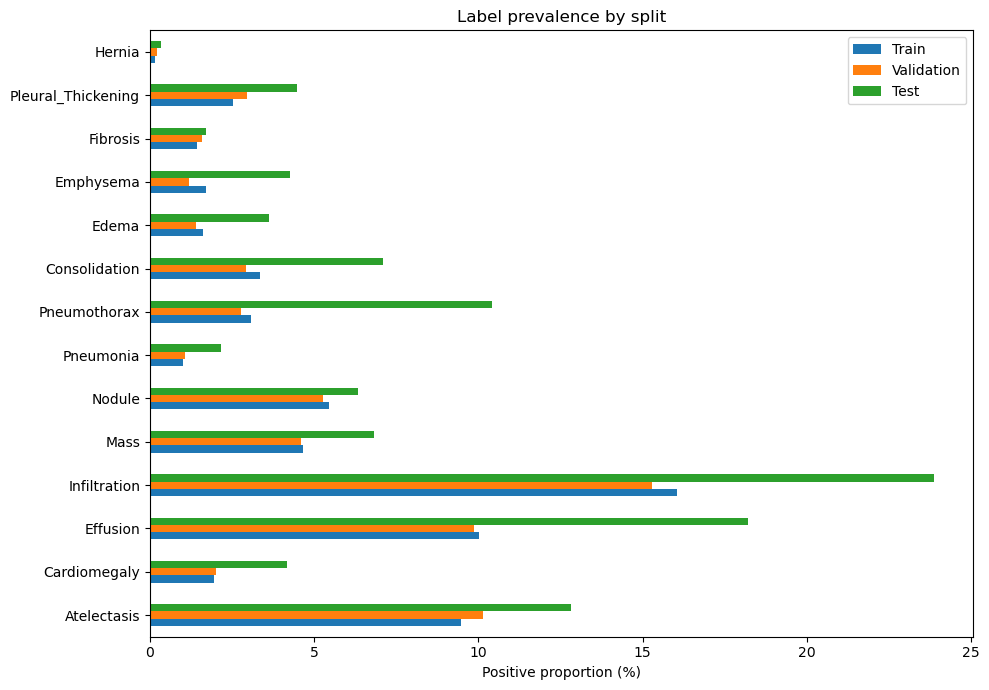

In [9]:
split_frames = {'Train': train_df, 'Validation': val_df, 'Test': test_df}
distribution = pd.DataFrame({name: frame[LABELS].sum() for name, frame in split_frames.items()})
distribution['All'] = distribution.sum(axis=1)
display(distribution)

distribution_percent = pd.DataFrame({
    name: frame[LABELS].mean() * 100
    for name, frame in split_frames.items()
})
display(distribution_percent.round(3))

distribution_percent.plot(kind='barh', figsize=(10, 7))
plt.xlabel('Positive proportion (%)')
plt.title('Label prevalence by split')
plt.tight_layout()
plt.show()

## 9. Save the processed metadata files

These CSV files are the main outputs of the dataset-processing stage. The model-training notebook can load them directly without repeating preprocessing.

In [10]:
save_columns = [
    'Image Index', 'Patient ID', 'View Position', 'image_path'
] + LABELS

for name, frame in [('all', df), ('train', train_df), ('validation', val_df), ('test', test_df)]:
    output_path = OUTPUT_ROOT / f'{name}.csv'
    frame[save_columns].to_csv(output_path, index=False)
    print('Saved:', output_path)

distribution.to_csv(OUTPUT_ROOT / 'class_distribution_counts.csv')
distribution_percent.to_csv(OUTPUT_ROOT / 'class_distribution_percent.csv')

summary = {
    'split_method': split_method,
    'total_images': int(len(df)),
    'total_patients': int(df['Patient ID'].nunique()),
    'train_images': int(len(train_df)),
    'validation_images': int(len(val_df)),
    'test_images': int(len(test_df)),
    'train_patients': int(train_df['Patient ID'].nunique()),
    'validation_patients': int(val_df['Patient ID'].nunique()),
    'test_patients': int(test_df['Patient ID'].nunique()),
    'view_position_counts': df['View Position'].value_counts().to_dict(),
}
(OUTPUT_ROOT / 'dataset_summary.json').write_text(json.dumps(summary, indent=2, default=int))
print('Saved summary:', OUTPUT_ROOT / 'dataset_summary.json')

Saved: /Users/eric/Downloads/ChestXray-NIHCC/processed_data/all.csv
Saved: /Users/eric/Downloads/ChestXray-NIHCC/processed_data/train.csv
Saved: /Users/eric/Downloads/ChestXray-NIHCC/processed_data/validation.csv
Saved: /Users/eric/Downloads/ChestXray-NIHCC/processed_data/test.csv
Saved summary: /Users/eric/Downloads/ChestXray-NIHCC/processed_data/dataset_summary.json


## 10. Visualize random X-rays and their labels

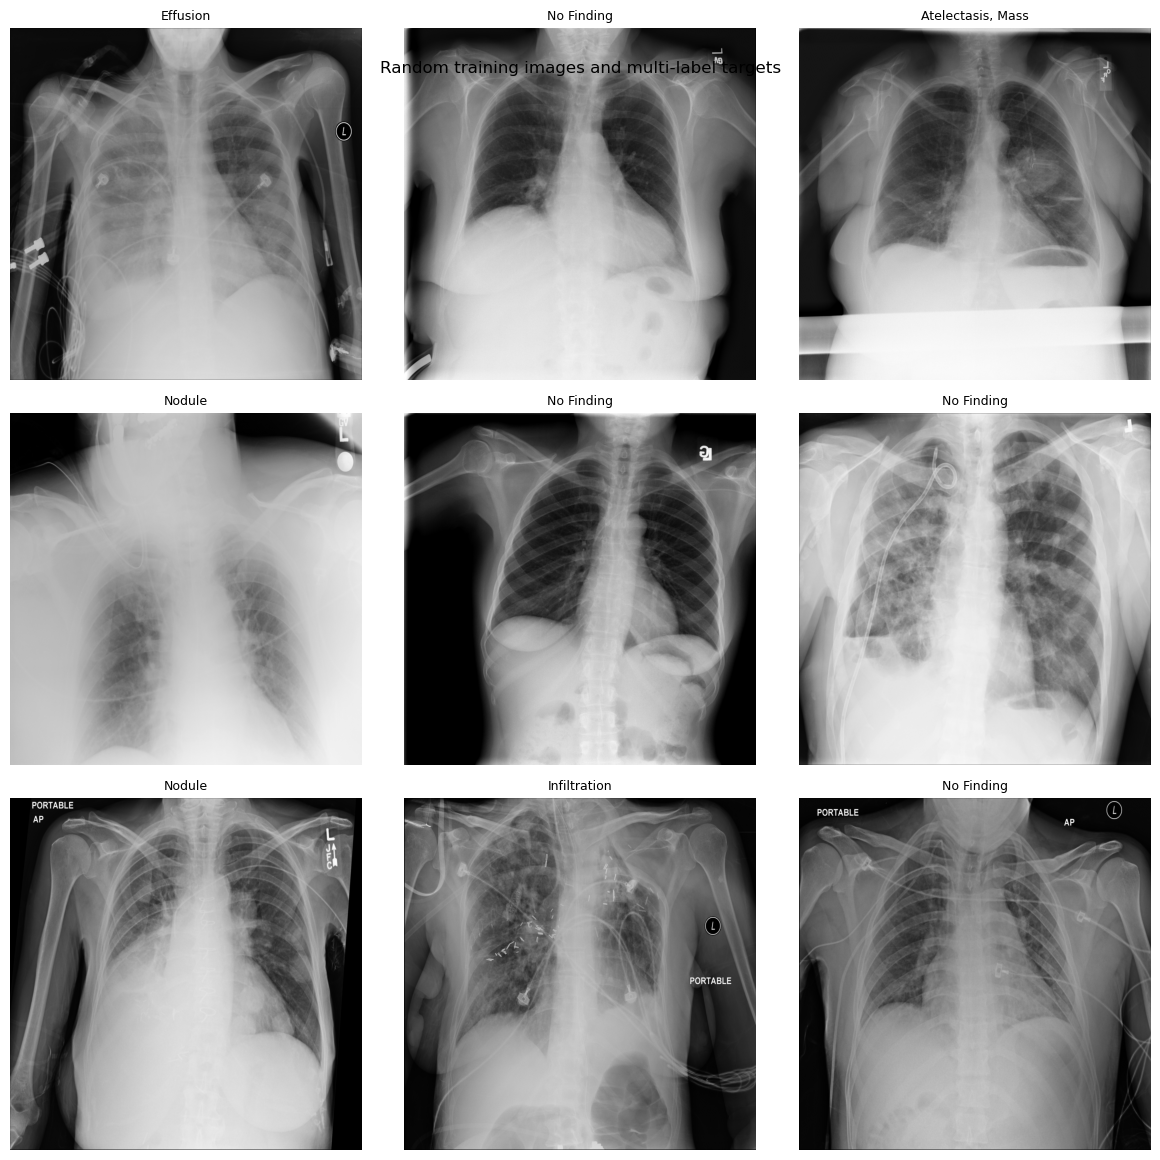

In [11]:
def labels_to_text(row):
    positive = [label for label in LABELS if row[label] == 1]
    return ', '.join(positive) if positive else 'No Finding'

sample = train_df.sample(n=min(9, len(train_df)), random_state=SEED)
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.ravel()

for ax, (_, row) in zip(axes, sample.iterrows()):
    image = Image.open(row['image_path']).convert('L')
    ax.imshow(image, cmap='gray')
    ax.set_title(labels_to_text(row), fontsize=9)
    ax.axis('off')

for ax in axes[len(sample):]:
    ax.axis('off')

plt.suptitle('Random training images and multi-label targets', y=0.92)
plt.tight_layout()
plt.show()

## 11. Create a PyTorch Dataset and run a smoke test

The smoke test only checks the data pipeline. It does not evaluate model quality. If this cell succeeds, each sample has the expected shape:

```text
image: 3 x 224 x 224
target: 14
```

In [12]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = Image.open(row['image_path']).convert('L')
        if self.transform:
            image = self.transform(image)
        target = torch.tensor(row[LABELS].to_numpy(dtype=np.float32))
        return image, target

train_dataset = ChestXrayDataset(train_df, train_transform)
val_dataset = ChestXrayDataset(val_df, eval_transform)
test_dataset = ChestXrayDataset(test_df, eval_transform)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=0)

images, targets = next(iter(train_loader))
print('Image batch shape:', images.shape)
print('Target batch shape:', targets.shape)
print('Image dtype:', images.dtype)
print('Target dtype:', targets.dtype)

assert images.shape[1:] == (3, 224, 224)
assert targets.shape[1] == 14
print('PASS: PyTorch data pipeline smoke test succeeded.')

Image batch shape: torch.Size([8, 3, 224, 224])
Target batch shape: torch.Size([8, 14])
Image dtype: torch.float32
Target dtype: torch.float32
PASS: PyTorch data pipeline smoke test succeeded.


## 12. Calculate `pos_weight` for imbalanced multi-label training

For the final training, use the training split only to calculate class weights. Do not use validation or test labels to determine training weights.

In [13]:
positive_counts = train_df[LABELS].sum().to_numpy(dtype=np.float32)
negative_counts = len(train_df) - positive_counts
pos_weight = negative_counts / np.maximum(positive_counts, 1.0)

pos_weight_df = pd.DataFrame({
    'label': LABELS,
    'positive_count': positive_counts.astype(int),
    'negative_count': negative_counts.astype(int),
    'pos_weight': pos_weight,
})
display(pos_weight_df)

pos_weight_tensor = torch.tensor(pos_weight, dtype=torch.float32)
criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
print(criterion)

,label,positive_count,negative_count,pos_weight
0,Atelectasis,7003,66913,9.554905
1,Cardiomegaly,1453,72463,49.871300
2,Effusion,7415,66501,8.968442
3,Infiltration,11853,62063,5.236058
4,Mass,3452,70464,20.412514
5,Nodule,4042,69874,17.286987
6,Pneumonia,742,73174,98.617249
7,Pneumothorax,2287,71629,31.320070
8,Consolidation,2482,71434,28.780823
9,Edema,1201,72715,60.545380


BCEWithLogitsLoss()


## 13. Final checklist before model training

The dataset-processing stage is complete only when all of the following are true:

1. All usable metadata rows have an image file.
2. Every target has exactly 14 binary values.
3. Train, validation, and test contain different patients.
4. The label distribution is documented.
5. The same image size and normalization will be used for all three models.
6. The smoke test returns images of shape `3 x 224 x 224` and targets of length `14`.
7. The processed CSV files and summary are saved under `processed_data/`.
